# Analiza danych z katalogu produktów

In [1]:
import json
import math
from datetime import date
from pathlib import Path
from urllib.parse import urlsplit

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

%matplotlib inline

PROJECT_DIR = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Lab1.md").is_file()),
    Path.cwd(),
)
DATA_DIR = PROJECT_DIR / "output"
ARTIFACT_DIR = DATA_DIR / "notebook_analysis"

required_files = ["products.json", "raw_listings.json", "run_summary.json"]
missing_files = [name for name in required_files if not (DATA_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(
        f"Brak plików w {DATA_DIR}: {', '.join(missing_files)}. "
        "Wskaż folder z wynikami scrapera w DATA_DIR."
    )

records = json.loads((DATA_DIR / "products.json").read_text(encoding="utf-8"))
raw_listings = json.loads((DATA_DIR / "raw_listings.json").read_text(encoding="utf-8"))
summary = json.loads((DATA_DIR / "run_summary.json").read_text(encoding="utf-8"))
if not records:
    raise ValueError("Plik products.json nie zawiera produktów.")

schema = summary["schema"]
df_raw = pd.DataFrame(records)
missing_columns = sorted(set(schema) - set(df_raw.columns))
extra_columns = sorted(set(df_raw.columns) - set(schema))
if missing_columns or extra_columns:
    raise ValueError(
        f"Niezgodność kolumn. Brakujące: {missing_columns}; dodatkowe: {extra_columns}"
    )
df_raw = df_raw[list(schema)]
comparison = summary.get("source_comparison", {})

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 65)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False})

if not summary.get("complete_lab_run", False):
    print("Uwaga: przebieg nie jest oznaczony jako pełny. "
          "Analiza obejmuje tylko zapisany zbiór.")


## 1. Kontrola jakości danych

### 1.1. Liczba rekordów i kolumn

In [2]:
basic_counts = pd.DataFrame([
    {"wielkość": "Wystąpienia ofert przed deduplikacją", "wartość": len(raw_listings)},
    {"wielkość": "Produkty w końcowym eksporcie", "wartość": len(df_raw)},
    {"wielkość": "Unikalne ID w końcowym eksporcie", "wartość": df_raw["id"].nunique()},
    {"wielkość": "Kolumny końcowego eksportu", "wartość": len(df_raw.columns)},
    {"wielkość": "Odwiedzone strony katalogu", "wartość": summary["page_count"]},
])
display(basic_counts)


,wielkość,wartość
0,Wystąpienia ofert przed deduplikacją,408
1,Produkty w końcowym eksporcie,400
2,Unikalne ID w końcowym eksporcie,400
3,Kolumny końcowego eksportu,29
4,Odwiedzone strony katalogu,5


### 1.2. Braki danych

In [3]:
missing_table = pd.DataFrame({
    "kolumna": df_raw.columns,
    "liczba braków": df_raw.isna().sum().to_numpy(),
    "braki [%]": (df_raw.isna().mean() * 100).round(2).to_numpy(),
})
display(missing_table)


,kolumna,liczba braków,braki [%]
0,id,0,0.0
1,name,0,0.0
2,price,0,0.0
3,currency,0,0.0
4,category,0,0.0
5,rarity,0,0.0
6,level,0,0.0
7,availability,0,0.0
8,rating,0,0.0
9,reviews,0,0.0


W kolumnach `seller` i `warranty_months` brakuje po 80 wartości (20%). Braki zostały celowo wprowadzone w serwisie. Pozostałe kolumny są kompletne.

### 1.3. Duplikaty

In [4]:
raw_ids = pd.Series([row.get("id") for row in raw_listings], dtype="string")
duplicates_before = int(raw_ids.duplicated().sum())
duplicates_after = int(df_raw["id"].duplicated().sum())

duplicate_table = pd.DataFrame([
    {"etap": "Przed deduplikacją", "wiersze": len(raw_listings),
     "unikalne ID": raw_ids.nunique(), "nadmiarowe wystąpienia": duplicates_before},
    {"etap": "Po deduplikacji", "wiersze": len(df_raw),
     "unikalne ID": df_raw["id"].nunique(), "nadmiarowe wystąpienia": duplicates_after},
])
display(duplicate_table)


,etap,wiersze,unikalne ID,nadmiarowe wystąpienia
0,Przed deduplikacją,408,400,8
1,Po deduplikacji,400,400,0


Osiem ofert powtarzało się na różnych stronach katalogu. Po deduplikacji każde ID występuje raz.

### 1.4. Typy kolumn

Typy wartości w JSON sprawdzono przed konwersją do typów pandas.

In [5]:
def valid_export_value(value, expected_type):
    if value is None:
        return True  # Braki są liczone osobno.
    if expected_type == "integer":
        return type(value) is int
    if expected_type == "number":
        return type(value) in (int, float) and math.isfinite(value)
    if expected_type == "date":
        if not isinstance(value, str):
            return False
        try:
            return date.fromisoformat(value).isoformat() == value
        except ValueError:
            return False
    if expected_type == "url":
        if not isinstance(value, str):
            return False
        parsed = urlsplit(value)
        return parsed.scheme in {"http", "https"} and bool(parsed.netloc)
    return isinstance(value, str)

original_dtypes = df_raw.dtypes.astype(str)
type_rows = []
for field, expected_type in schema.items():
    invalid = [
        (row.get("id"), row.get(field))
        for row in records
        if not valid_export_value(row.get(field), expected_type)
    ]
    type_rows.append({
        "kolumna": field,
        "oczekiwany typ": expected_type,
        "typ pandas przed ustawieniem": original_dtypes[field],
        "błędne wartości JSON": len(invalid),
        "przykłady błędów": repr(invalid[:3]) if invalid else "",
    })

type_table = pd.DataFrame(type_rows)
invalid_type_count = int(type_table["błędne wartości JSON"].sum())
if invalid_type_count:
    raise ValueError(
        f"Wykryto {invalid_type_count} wartości o niepoprawnym typie. "
        "Sprawdź eksport przed wykonywaniem statystyk."
    )

df = df_raw.copy()
for field, expected_type in schema.items():
    if expected_type == "integer":
        df[field] = df[field].astype("Int64")
    elif expected_type == "number":
        df[field] = df[field].astype("Float64")
    elif expected_type == "date":
        df[field] = pd.to_datetime(df[field], format="%Y-%m-%d", errors="raise")
    else:
        df[field] = df[field].astype("string")

type_table["typ pandas do obliczeń"] = type_table["kolumna"].map(df.dtypes.astype(str))
display(type_table[["kolumna", "oczekiwany typ", "typ pandas przed ustawieniem", "typ pandas do obliczeń",
                    "błędne wartości JSON"]])


,kolumna,oczekiwany typ,typ pandas przed ustawieniem,typ pandas do obliczeń,błędne wartości JSON
0,id,integer,int64,Int64,0
1,name,string,str,string,0
2,price,number,float64,Float64,0
3,currency,string,str,string,0
4,category,string,str,string,0
5,rarity,string,str,string,0
6,level,integer,int64,Int64,0
7,availability,string,str,string,0
8,rating,number,float64,Float64,0
9,reviews,integer,int64,Int64,0


W eksporcie nie wykryto wartości o błędnym typie. Kolumny liczbowe zawierają liczby.

### 1.5. Zgodność ze źródłem

In [6]:
source_differences = comparison.get("differences", [])
source_checks = pd.DataFrame([
    {"kontrola": "Liczba produktów w źródle", "wynik": comparison.get("source_product_count")},
    {"kontrola": "Różnice wartości pól", "wynik": len(source_differences)},
    {"kontrola": "Brakujące ID ofert", "wynik": len(comparison.get("missing_listing_ids", []))},
    {"kontrola": "Nieoczekiwane ID ofert", "wynik": len(comparison.get("unexpected_listing_ids", []))},
    {"kontrola": "Brakujące szczegóły", "wynik": len(comparison.get("missing_detail_ids", []))},
    {"kontrola": "Zebrano wszystkie ID ze źródła",
     "wynik": comparison.get("all_source_ids_collected", False)},
])
display(source_checks)
if source_differences:
    display(pd.DataFrame(source_differences))

numeric_fields = [
    field for field, kind in schema.items()
    if kind in {"integer", "number"} and field != "id"
]
currency_counts = df["currency"].value_counts()
primary_currency = str(currency_counts.index[0])
primary = df.loc[df["currency"] == primary_currency]
analysis_groups = [
    (field, "wszystkie", df) for field in numeric_fields if field != "price"
]
analysis_groups += [
    ("price", str(currency), group)
    for currency, group in df.groupby("currency", dropna=True)
]
display(currency_counts.rename_axis("waluta").reset_index(name="liczba produktów"))


,kontrola,wynik
0,Liczba produktów w źródle,400
1,Różnice wartości pól,0
2,Brakujące ID ofert,0
3,Nieoczekiwane ID ofert,0
4,Brakujące szczegóły,0
5,Zebrano wszystkie ID ze źródła,True


,waluta,liczba produktów
0,PLN,343
1,EUR,36
2,USD,21


Porównanie zapisane przez scraper nie wykazało różnic pól względem źródłowego JSON-a.

### 1.6. Wartości odstające

Zastosowano granice Q1 − 1,5 × IQR i Q3 + 1,5 × IQR, gdzie IQR = Q3 − Q1. Pominięto ID, a ceny sprawdzono osobno dla każdej waluty.

In [7]:
difference_pairs = {
    (str(entry.get("id")), entry.get("field")) for entry in source_differences
}
iqr_rows = []
outlier_rows = []

for field, group_name, group in analysis_groups:
    values = group[field].dropna().astype(float)
    if values.empty:
        continue
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = float(q1 - 1.5 * iqr), float(q3 + 1.5 * iqr)
    candidates = group.loc[(group[field] < lower) | (group[field] > upper)]

    iqr_rows.append({
        "cecha": field, "grupa": group_name, "Q1": q1, "Q3": q3, "IQR": iqr,
        "dolna granica": lower, "górna granica": upper,
        "liczba odstających": len(candidates),
    })
    for _, row in candidates.iterrows():
        product_id = int(row["id"])
        if (str(product_id), field) in difference_pairs:
            interpretation = "Różnica względem źródła: podejrzenie błędu parsera."
        elif comparison and comparison.get("all_source_ids_collected", False):
            interpretation = (
                "Według kontroli ze scrapowania wartość występuje także w źródle; "
                "to skrajność danych, a nie sama w sobie błąd odczytu."
            )
        else:
            interpretation = "Brak pełnej kontroli źródła: wymaga ręcznego sprawdzenia."
        outlier_rows.append({
            "id": product_id, "cecha": field, "grupa": group_name,
            "wartość": float(row[field]), "dolna granica": lower,
            "górna granica": upper, "interpretacja": interpretation,
        })

iqr_table = pd.DataFrame(iqr_rows)
outliers_table = pd.DataFrame(outlier_rows, columns=[
    "id", "cecha", "grupa", "wartość", "dolna granica", "górna granica", "interpretacja"
])
display(iqr_table.round(3))

if not outliers_table.empty:
    display(outliers_table)


,cecha,grupa,Q1,Q3,IQR,dolna granica,górna granica,liczba odstających
0,level,wszystkie,30.00,40.000,10.000,15.000,55.000,0
1,rating,wszystkie,3.10,4.300,1.200,1.300,6.100,0
2,reviews,wszystkie,58.75,176.000,117.250,-117.125,351.875,0
3,weight_g,wszystkie,870.75,3288.250,2417.500,-2755.500,6914.500,0
4,stock,wszystkie,13.00,65.000,52.000,-65.000,143.000,0
5,warranty_months,wszystkie,6.00,24.000,18.000,-21.000,51.000,0
6,favorites,wszystkie,73.75,220.250,146.500,-146.000,440.000,0
7,views,wszystkie,1991.75,5677.250,3685.500,-3536.500,11205.500,0
8,return_days,wszystkie,14.00,30.000,16.000,-10.000,54.000,0
9,price,EUR,512.72,652.415,139.695,303.178,861.957,0


Reguła IQR nie wskazała wartości odstających. Porównanie ze źródłem również nie wykazało błędów cen; nie stwierdzono anomalii wymagających korekty.

### 1.7. Wniosek o poprawności parsera

In [8]:
required_fields = ["id", "name", "price", "currency", "url"]
rejected_count = sum(summary.get("rejected_values", {}).values())

quality_checks = {
    "Liczba produktów zgodna z podsumowaniem": len(df) == summary["record_count"],
    "Liczba ofert zgodna z podsumowaniem": len(raw_listings) == summary["listing_count"],
    "Liczba duplikatów zgodna z podsumowaniem":
        duplicates_before == summary["duplicates_before"],
    "Brak duplikatów w końcowym eksporcie": duplicates_after == 0,
    "Brak błędnych typów w eksporcie JSON": invalid_type_count == 0,
    "Brak pustych wartości w polach podstawowych":
        not df[required_fields].isna().any().any(),
    "Scraper nie odrzucił błędnych wartości": rejected_count == 0,
    "Zapisane porównanie ze źródłem bez różnic":
        bool(comparison) and not source_differences,
    "Wszystkie ID źródła zostały zebrane":
        comparison.get("all_source_ids_collected", False),
    "Brak pominiętych ofert i szczegółów":
        bool(comparison)
        and not comparison.get("missing_listing_ids", [])
        and not comparison.get("unexpected_listing_ids", [])
        and not comparison.get("missing_detail_ids", []),
    "Pełny przebieg według podsumowania": summary.get("complete_lab_run", False),
}
quality_table = pd.DataFrame([
    {"kontrola": name, "wynik": "OK" if bool(passed) else "DO SPRAWDZENIA"}
    for name, passed in quality_checks.items()
])
display(quality_table)

quality_ok = all(bool(value) for value in quality_checks.values())


,kontrola,wynik
0,Liczba produktów zgodna z podsumowaniem,OK
1,Liczba ofert zgodna z podsumowaniem,OK
2,Liczba duplikatów zgodna z podsumowaniem,OK
3,Brak duplikatów w końcowym eksporcie,OK
4,Brak błędnych typów w eksporcie JSON,OK
5,Brak pustych wartości w polach podstawowych,OK
6,Scraper nie odrzucił błędnych wartości,OK
7,Zapisane porównanie ze źródłem bez różnic,OK
8,Wszystkie ID źródła zostały zebrane,OK
9,Brak pominiętych ofert i szczegółów,OK


Kontrola potwierdziła kompletność zbioru, usunięcie duplikatów i zgodność odczytanych pól ze źródłem. Parser poprawnie obsłużył waluty, formaty liczb i braki danych. Po tej kontroli nie były potrzebne dodatkowe poprawki parsera.

## 2. Statystyki opisowe

Statystyki obliczono z danych, z pominięciem ID i braków. Ceny zestawiono osobno dla każdej waluty. Mediana odpowiada kwartylowi Q2; `n` oznacza liczbę dostępnych obserwacji.

In [9]:
def descriptive_statistics(values):
    values = values.dropna().astype(float)
    if values.empty:
        return None, []
    frequencies = values.value_counts()
    mode_frequency = int(frequencies.max())
    modes = values.mode().tolist()
    if mode_frequency == 1:
        mode_label = "brak dominującej wartości (wszystkie różne)"
    else:
        mode_label = ", ".join(f"{value:g}" for value in modes[:5])
        if len(modes) > 5:
            mode_label += f" ... (łącznie {len(modes)} mód)"
    return {
        "n": len(values),
        "średnia": float(values.mean()),
        "mediana / Q2": float(values.median()),
        "moda": mode_label,
        "częstość mody": mode_frequency,
        "Q1": float(values.quantile(0.25)),
        "Q3": float(values.quantile(0.75)),
        "minimum": float(values.min()),
        "maksimum": float(values.max()),
    }, modes

statistics_rows = []
modes_full = {}
for field, group_name, group in analysis_groups:
    result, modes = descriptive_statistics(group[field])
    if result is not None:
        statistics_rows.append({"cecha": field, "grupa": group_name, **result})
        modes_full[(field, group_name)] = modes

statistics_table = pd.DataFrame(statistics_rows)
display(statistics_table.round(3))


,cecha,grupa,n,średnia,mediana / Q2,moda,częstość mody,Q1,Q3,minimum,maksimum
0,level,wszystkie,400,34.520,35.00,40,124,30.00,40.000,20.00,41.00
1,rating,wszystkie,400,3.700,3.70,"2.5, 2.6, 2.7, 2.8, 2.9 ... (łącznie 25 mód)",16,3.10,4.300,2.50,4.90
2,reviews,wszystkie,400,117.700,117.00,"1, 3, 5, 6, 7 ... (łącznie 160 mód)",2,58.75,176.000,0.00,239.00
3,weight_g,wszystkie,400,2083.900,1720.50,brak dominującej wartości (wszystkie różne),1,870.75,3288.250,21.00,4984.00
4,stock,wszystkie,400,38.935,39.00,13,58,13.00,65.000,0.00,78.00
5,warranty_months,wszystkie,320,14.025,12.00,"12, 24",107,6.00,24.000,6.00,24.00
6,favorites,wszystkie,400,147.500,146.50,"2, 5, 8, 11, 13 ... (łącznie 100 mód)",2,73.75,220.250,0.00,299.00
7,views,wszystkie,400,3858.500,3834.50,brak dominującej wartości (wszystkie różne),1,1991.75,5677.250,149.00,8112.00
8,return_days,wszystkie,400,21.665,21.00,21,134,14.00,30.000,14.00,30.00
9,price,EUR,36,581.364,583.06,brak dominującej wartości (wszystkie różne),1,512.72,652.415,347.40,812.79


Długie listy mód skrócono w tabeli. Pełne listy zapisano w pliku `statystyki.csv`.

## 3. Histogram cen

Wykres obejmuje 343 produkty z cenami w PLN.

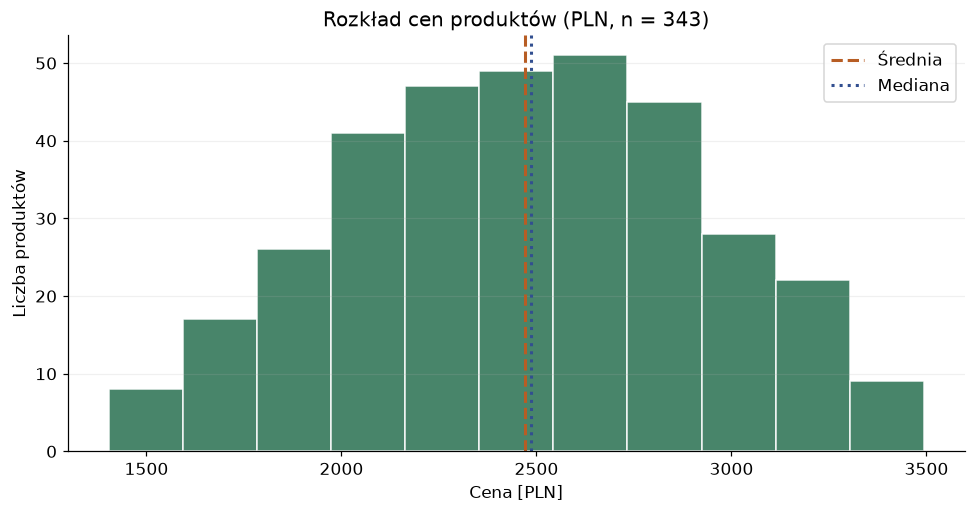

In [10]:
prices = primary["price"].dropna().astype(float)
mean_price = float(prices.mean())
median_price = float(prices.median())

fig, ax = plt.subplots(figsize=(9, 4.8))
hist_counts, hist_edges, _ = ax.hist(
    prices, bins="auto", color="#34785a", edgecolor="white", alpha=0.9
)
ax.axvline(mean_price, color="#b75d24", linewidth=2, linestyle="--", label="Średnia")
ax.axvline(median_price, color="#324f90", linewidth=2, linestyle=":", label="Mediana")
ax.set(
    title=f"Rozkład cen produktów ({primary_currency}, n = {len(prices)})",
    xlabel=f"Cena [{primary_currency}]",
    ylabel="Liczba produktów",
)
ax.legend()
ax.grid(axis="y", alpha=0.18)
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "histogram_cen.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)


Najwięcej produktów znajduje się w środkowych przedziałach cenowych, a najmniej na krańcach rozkładu. Średnia i mediana są zbliżone.

## 4. Wykres pudełkowy cen

Każda waluta ma osobną skalę. Mediany i kwartyle obliczono z danych i podano w tabeli statystyk opisowych.

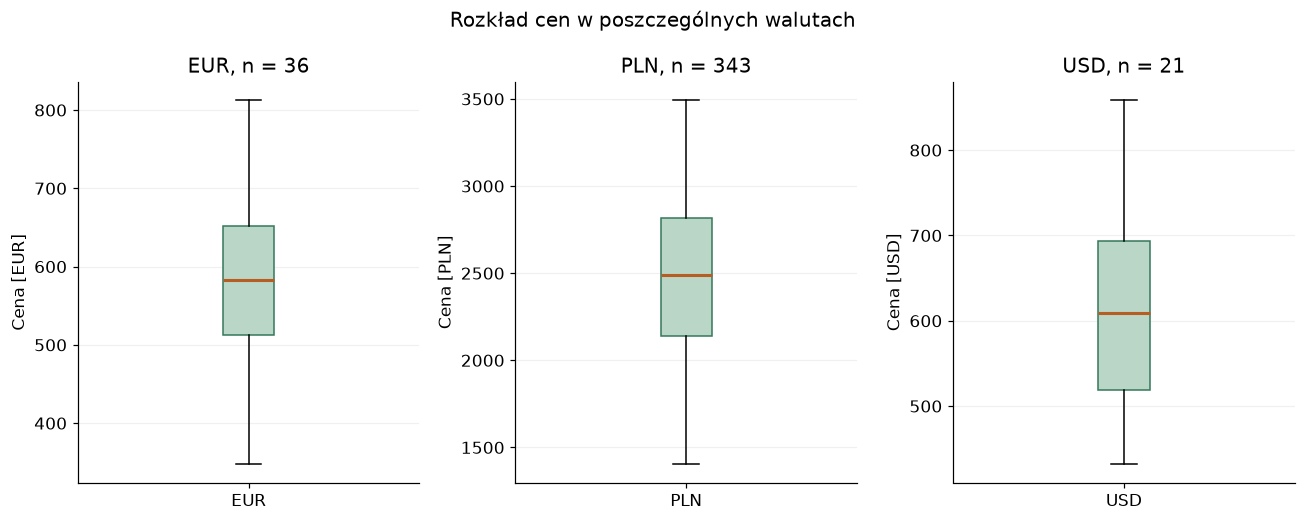

In [11]:
currencies = sorted(str(currency) for currency in currency_counts.index)
fig, axes = plt.subplots(
    1, len(currencies), figsize=(4 * len(currencies), 4.8), squeeze=False
)

for ax, currency in zip(axes[0], currencies):
    values = df.loc[df["currency"] == currency, "price"].dropna().astype(float)
    ax.boxplot(
        values, tick_labels=[currency], patch_artist=True,
        boxprops={"facecolor": "#b9d6c7", "edgecolor": "#34785a"},
        medianprops={"color": "#b75d24", "linewidth": 2},
    )
    ax.set(title=f"{currency}, n = {len(values)}", ylabel=f"Cena [{currency}]")
    ax.grid(axis="y", alpha=0.18)

fig.suptitle("Rozkład cen w poszczególnych walutach")
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "boxplot_cen.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)


W żadnej grupie walutowej nie wykryto cen odstających według reguły 1,5 × IQR.

## 5. Korelacja poziomu przedmiotu i ceny

Korelację Pearsona obliczono osobno dla każdej waluty.

,waluta,liczba par,r Pearsona
0,EUR,36,0.7379
1,PLN,343,0.7793
2,USD,21,0.7913


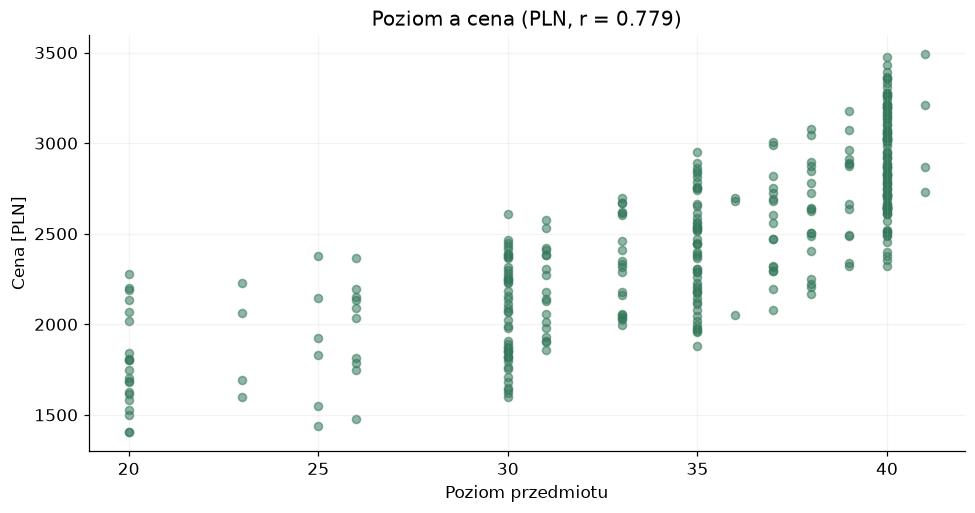

In [12]:
correlation_rows = []
for currency in currencies:
    pairs = df.loc[df["currency"] == currency, ["level", "price"]].dropna().astype(float)
    if len(pairs) >= 2 and pairs["level"].nunique() > 1 and pairs["price"].nunique() > 1:
        coefficient = float(pairs.corr(method="pearson").loc["level", "price"])
    else:
        coefficient = None
    correlation_rows.append({
        "waluta": currency, "liczba par": len(pairs), "r Pearsona": coefficient
    })

correlation_table = pd.DataFrame(correlation_rows)
display(correlation_table.round(4))

pairs = primary[["level", "price"]].dropna().astype(float)
primary_r_value = correlation_table.loc[
    correlation_table["waluta"] == primary_currency, "r Pearsona"
].iloc[0]
primary_r = None if pd.isna(primary_r_value) else float(primary_r_value)
r_label = "nieokreślony" if primary_r is None else f"{primary_r:.3f}"

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.scatter(pairs["level"], pairs["price"], color="#34785a", alpha=0.55, s=28)
ax.set(
    title=f"Poziom a cena ({primary_currency}, r = {r_label})",
    xlabel="Poziom przedmiotu",
    ylabel=f"Cena [{primary_currency}]",
)
ax.grid(alpha=0.15)
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "korelacja_poziom_cena.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)


Dla 343 produktów w PLN korelacja wynosi **r = 0,779**. Wyższym poziomom przedmiotów zwykle towarzyszą wyższe ceny. W generatorze poziom jest jednym ze składników ceny, więc zależność ma uzasadnienie w sposobie tworzenia danych. Wynik dotyczy sztucznego katalogu i nie dowodzi przyczynowości.

## 6. Zapis wyników

Tabele i wykresy zapisano w `output/notebook_analysis/`.

In [13]:
tables_to_save = {
    "liczebnosci.csv": basic_counts,
    "braki.csv": missing_table,
    "duplikaty.csv": duplicate_table,
    "typy_kolumn.csv": type_table,
    "kontrola_jakosci.csv": quality_table,
    "granice_iqr.csv": iqr_table,
    "wartosci_odstajace.csv": outliers_table,
    "korelacja.csv": correlation_table,
}
for filename, table in tables_to_save.items():
    table.to_csv(ARTIFACT_DIR / filename, index=False, encoding="utf-8-sig")

statistics_export = statistics_table.copy()
statistics_export["wszystkie mody"] = [
    json.dumps(modes_full[(row["cecha"], row["grupa"])], ensure_ascii=False)
    for _, row in statistics_export.iterrows()
]
statistics_export.to_csv(
    ARTIFACT_DIR / "statystyki.csv", index=False, encoding="utf-8-sig"
)

analysis_summary = {
    "record_count": len(df),
    "attribute_count": len(df.columns),
    "duplicates_before": duplicates_before,
    "duplicates_after": duplicates_after,
    "invalid_type_count": invalid_type_count,
    "source_difference_count": len(source_differences),
    "outlier_count": len(outliers_table),
    "quality_ok": quality_ok,
    "primary_currency": primary_currency,
    "primary_correlation_records": len(pairs),
    "pearson_r": primary_r,
    "checks": {name: bool(value) for name, value in quality_checks.items()},
}
_ = (ARTIFACT_DIR / "podsumowanie.json").write_text(
    json.dumps(analysis_summary, ensure_ascii=False, indent=2, allow_nan=False) + "\n",
    encoding="utf-8",
)
